# QDiabetes-2018 Model A — Validation & Gap Analysis (Synthetic UAE Cohort)

**SYNTHETIC — NOT REAL PATIENT DATA**

**Important:** The synthetic diabetes outcome was generated from the data-generator's latent risk trajectory — **not** from QDiabetes' formula, and ethnicity was never wired into that outcome. Therefore **neither discrimination nor calibration here is evidence about real-world UAE performance**. This notebook validates that the pipeline and metrics run correctly and previews the analysis that will run on real NABIDH data.

Evaluates QDiabetes-2018 Model A using the **original paper success metrics** (Hippisley-Cox & Coupland, BMJ 2017/2018):

| Metric | Ideal | Interpretation |
|--------|-------|----------------|
| **C-statistic** | → 1.0 | Discrimination (ranking high-risk vs low-risk) |
| **D statistic** | higher | Separation between outcome groups |
| **R²** | higher | Explained variation |
| **Calibration slope** | 1.0 | Logistic regression coef: outcome ~ logit(predicted prob) |
| **O:E ratio** | 1.0 | Observed event rate / mean predicted risk |

**Gap analysis** compares metrics across subgroups. Subgroups with **<50 outcome events** show `insufficient events` for C/R²/calibration slope and are excluded from headline gap rankings.

**Outcome:** incident type 2 diabetes (E11 / defining labs / A10) after index, excluding prevalent/T1D at baseline.

**Requirements:** `pip install pandas numpy matplotlib seaborn scikit-learn`

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve

from qdiabetes_cohort import (
    MIN_EVENTS_GAP,
    add_gaps,
    build_validation_cohort,
    calibration_consistency_note,
    load_tables,
    qdiabetes_validation_metrics,
    subgroup_metrics,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

UK_BENCHMARKS = {
    "c_statistic_female": 0.87,
    "c_statistic_male": 0.86,
    "r2_female": 0.56,
    "r2_male": 0.53,
    "calibration_slope": 1.0,
    "oe_ratio": 1.0,
}

## 1. Build validation cohort & score

In [2]:
tables = load_tables("output")
df, eligible, funnel = build_validation_cohort(tables, return_eligible=True, return_funnel=True)

print("Cohort funnel (LOOKBACK_DAYS=365 index):")
print(f"  Total patients: {funnel['total_patients']:,}")
print(f"  Excluded — insufficient lookback: {funnel['excluded_insufficient_lookback']:,}")
print(f"  Excluded — T1D at/before index: {funnel['excluded_t1d_at_baseline']:,}")
print(f"  Excluded — prevalent T2D at/before index: {funnel['excluded_prevalent_t2d_at_baseline']:,}")
print(f"  Eligible scoring cohort: {funnel['eligible_cohort']:,}")
print(f"Scoring cohort (no DM/T1D at index): {len(eligible):,}")
print(
    f"Incident T2D after index — full scoring cohort: "
    f"{eligible['outcome_t2d'].sum():,} / {len(eligible):,} "
    f"({100 * eligible['outcome_t2d'].mean():.1f}%)"
)
print(f"Scoreable patients (BMI present): {len(df):,}")
print(
    f"Incident T2D after index — BMI-scoreable subset: "
    f"{df['outcome_t2d'].sum():,} / {len(df):,} "
    f"({100 * df['outcome_t2d'].mean():.1f}%)"
)
print(f"Median follow-up (years): {df['followup_years'].median():.1f}")
df[["risk_10y_pct", "outcome_t2d", "followup_years"]].describe()

Cohort funnel (LOOKBACK_DAYS=365 index):
  Total patients: 100,000
  Excluded — insufficient lookback: 21,446
  Excluded — T1D at/before index: 421
  Excluded — prevalent T2D at/before index: 15,055
  Eligible scoring cohort: 63,078
Scoring cohort (no DM/T1D at index): 63,078
Incident T2D after index — full scoring cohort: 6,299 / 63,078 (10.0%)
Scoreable patients (BMI present): 43,832
Incident T2D after index — BMI-scoreable subset: 4,489 / 43,832 (10.2%)
Median follow-up (years): 4.8


,risk_10y_pct,followup_years
count,43832.000000,43832.000000
mean,14.186559,4.503150
std,16.164732,1.696492
min,0.049519,0.002738
25%,2.978594,3.890486
50%,8.190441,4.813142
75%,19.206093,5.722793
max,99.991072,6.997947


## 2. Overall performance — original success metrics

,metric,synthetic_uae,uk_benchmark
0,C-statistic,0.579,0.865
1,D statistic,0.259,NaN
2,R²,0.039,0.545
3,Calibration slope,0.184,1.000
4,O:E ratio,0.722,1.000
5,Brier score,0.112,NaN
6,Event rate (%),10.241,NaN
7,Mean predicted 10y risk (%),14.187,NaN


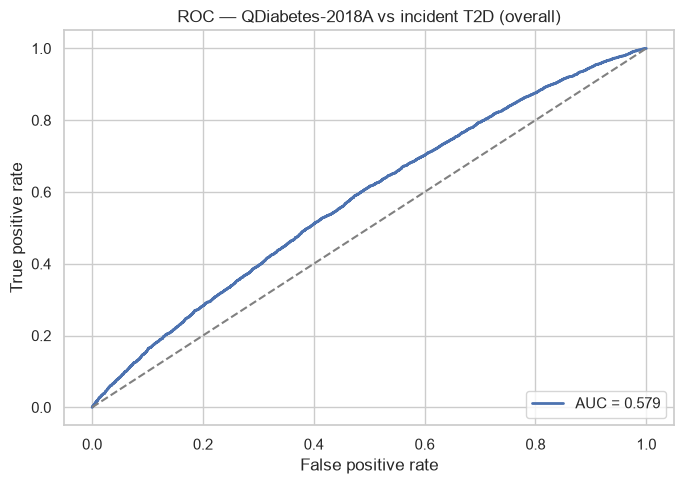

In [3]:
overall = qdiabetes_validation_metrics(df["outcome_t2d"].to_numpy(), df["risk_10y_pct"].to_numpy())

overall_tbl = pd.DataFrame({
    "metric": [
        "C-statistic",
        "D statistic",
        "R²",
        "Calibration slope",
        "O:E ratio",
        "Brier score",
        "Event rate (%)",
        "Mean predicted 10y risk (%)",
    ],
    "synthetic_uae": [
        overall["c_statistic"],
        overall["d_statistic"],
        overall["r2"],
        overall["calibration_slope"],
        overall["oe_ratio"],
        overall["brier"],
        overall["event_rate_pct"],
        overall["mean_predicted_pct"],
    ],
    "uk_benchmark": [0.865, np.nan, 0.545, 1.0, 1.0, np.nan, np.nan, np.nan],
})
display(overall_tbl.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
fpr, tpr, _ = roc_curve(df["outcome_t2d"], df["risk_10y_pct"])
ax.plot(fpr, tpr, lw=2, label=f"AUC = {overall['c_statistic']:.3f}")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC — QDiabetes-2018A vs incident T2D (overall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 3. Calibration plot (risk deciles)

,risk_decile,n,events,predicted_mean,observed_rate,observed_pct,predicted_pct,oe_decile
0,"(0.0485, 1.006]",4384,253,0.006,0.058,5.771,0.553,10.444
1,"(1.006, 2.197]",4383,329,0.016,0.075,7.506,1.563,4.801
2,"(2.197, 3.831]",4383,387,0.030,0.088,8.830,2.988,2.955
3,"(3.831, 5.78]",4383,404,0.048,0.092,9.217,4.773,1.931
4,"(5.78, 8.19]",4383,412,0.069,0.094,9.400,6.939,1.355
5,"(8.19, 11.519]",4383,463,0.098,0.106,10.564,9.778,1.080
6,"(11.519, 16.093]",4383,510,0.137,0.116,11.636,13.657,0.852
7,"(16.093, 23.131]",4383,503,0.193,0.115,11.476,19.333,0.594
8,"(23.131, 36.647]",4383,556,0.290,0.127,12.685,28.979,0.438
9,"(36.647, 99.991]",4384,672,0.533,0.153,15.328,53.297,0.288


Calibration consistency: slope=0.184 with C=0.579 — review decile plot if slope looks extreme; decile observed rates do not rise monotonically.


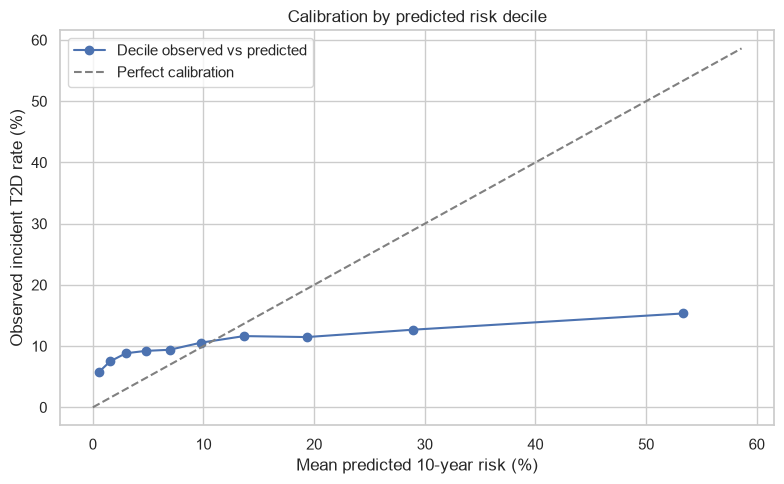

In [4]:
cal = df.copy()
cal["risk_decile"] = pd.qcut(cal["risk_10y_pct"], 10, duplicates="drop")
cal_sum = cal.groupby("risk_decile", observed=True).agg(
    n=("outcome_t2d", "count"),
    events=("outcome_t2d", "sum"),
    predicted_mean=("risk_10y_pct", lambda s: s.mean() / 100),
    observed_rate=("outcome_t2d", "mean"),
).reset_index()
cal_sum["observed_pct"] = 100 * cal_sum["observed_rate"]
cal_sum["predicted_pct"] = 100 * cal_sum["predicted_mean"]
cal_sum["oe_decile"] = cal_sum["observed_rate"] / cal_sum["predicted_mean"]
display(cal_sum.round(3))

print(calibration_consistency_note(
    overall["calibration_slope"],
    overall["c_statistic"],
    decile_slopes=cal_sum["observed_pct"].tolist(),
))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(cal_sum["predicted_pct"], cal_sum["observed_pct"], "o-", color="#4C72B0", label="Decile observed vs predicted")
lim = max(cal_sum["predicted_pct"].max(), cal_sum["observed_pct"].max()) * 1.1
ax.plot([0, lim], [0, lim], "--", color="gray", label="Perfect calibration")
ax.set_xlabel("Mean predicted 10-year risk (%)")
ax.set_ylabel("Observed incident T2D rate (%)")
ax.set_title("Calibration by predicted risk decile")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Gap analysis framework

For each subgroup we compute the same metrics and **gaps vs overall** (only subgroups with ≥50 outcome events contribute to headline gap rankings):
- ΔC = C_subgroup − C_overall
- ΔR² = R²_subgroup − R²_overall
- Δcalibration = slope_subgroup − slope_overall
- ΔO:E = O:E_subgroup − O:E_overall

`subgroup_metrics`, `add_gaps`, and `qdiabetes_validation_metrics` are imported from `qdiabetes_cohort` (single source of truth).

In [5]:
# subgroup_metrics / add_gaps imported from qdiabetes_cohort
print("Gap analysis requires ≥" + str(MIN_EVENTS_GAP) + " outcome events for C/R²/calibration slope.")

Gap analysis requires ≥50 outcome events for C/R²/calibration slope.


## 5. Gap by QDiabetes ethnicity

> **Synthetic-data caveat:** Near-flat C-statistics and event rates across ethnic groups are **expected** — ethnicity does not affect the synthetic outcome. Between-group differences are noise, not evidence about QDiabetes transportability.

,group,n,events,event_rate_pct,c_statistic,r2,calibration_slope,oe_ratio,metrics_note,gap_c,gap_r2,gap_oe
5,Pakistani,5174.0,530.0,10.244,0.545,0.025,0.119,0.535,,-0.034,-0.015,-0.187
4,OtherAsian,6592.0,656.0,9.951,0.580,0.048,0.198,0.601,,0.001,0.009,-0.121
3,Other,11323.0,1188.0,10.492,0.585,0.051,0.226,1.157,,0.006,0.012,0.435
6,WhiteNA,3880.0,398.0,10.258,0.589,0.054,0.235,1.621,,0.010,0.015,0.899
2,Indian,12410.0,1245.0,10.032,0.592,0.056,0.231,0.631,,0.013,0.017,-0.091
0,Bangladeshi,2690.0,282.0,10.483,0.601,0.046,0.202,0.404,,0.022,0.007,-0.318
1,BlackAfrican,1763.0,190.0,10.777,0.621,0.071,0.298,0.991,,0.042,0.032,0.269


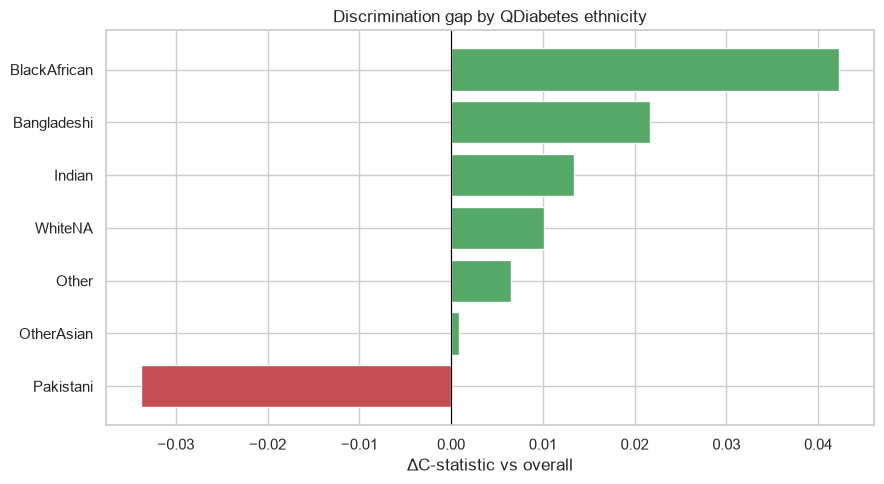

In [6]:
eth_q = subgroup_metrics(df, "QDiabetes ethnicity", "ethn_qdiabetes")
eth_q = add_gaps(eth_q, overall)
display(eth_q[["group", "n", "events", "event_rate_pct", "c_statistic", "r2", "calibration_slope", "oe_ratio", "metrics_note", "gap_c", "gap_r2", "gap_oe"]].round(3))

fig, ax = plt.subplots(figsize=(9, 5))
colors = eth_q["gap_c"].apply(lambda x: "#C44E52" if x < 0 else "#55A868")
ax.barh(eth_q["group"], eth_q["gap_c"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("ΔC-statistic vs overall")
ax.set_title("Discrimination gap by QDiabetes ethnicity")
plt.tight_layout()
plt.show()

## 6. Gap by NABIDH ethnicity — mapping structural limitation

> **Do not read subgroup C-statistics here as performance findings.** The one insight that does **not** depend on the synthetic outcome: mapping Emirati/Gulf Arab to QDiabetes **Other** assigns a low ethnicity coefficient (near White). In a genuinely high-risk Gulf population this mapping would **systematically under-predict** risk — a prediction-side structural limitation to test on real NABIDH data.

In [7]:
eth_n = subgroup_metrics(df, "NABIDH ethnicity", "ethnicity_nabidh", min_n=500)
eth_n = add_gaps(eth_n, overall)
display(eth_n[["group", "n", "events", "c_statistic", "r2", "calibration_slope", "metrics_note", "gap_c", "gap_oe"]].round(3))

# Emirati vs non-Emirati — mapping check only (not a performance finding)
df["emirati_group"] = np.where(df["is_emirati"], "Emirati", "Non-Emirati")
emirati_gap = subgroup_metrics(df, "Emirati flag", "emirati_group")
emirati_gap = add_gaps(emirati_gap, overall)
print("\nEmirati mapping (Emirati coded as QDiabetes 'Other') — structural, not outcome-based:")
display(emirati_gap[["group", "n", "events", "mean_predicted_pct", "c_statistic", "metrics_note", "gap_c"]].round(3))

,group,n,events,c_statistic,r2,calibration_slope,metrics_note,gap_c,gap_oe
9,Pakistani,5174.0,530.0,0.545,0.025,0.119,,-0.034,-0.187
10,Western,1258.0,122.0,0.570,0.009,0.172,,-0.009,0.777
8,Other Asian,3472.0,353.0,0.571,0.034,0.175,,-0.007,-0.112
1,Arab (non-Gulf),1283.0,140.0,0.573,0.022,0.183,,-0.006,0.516
3,Emirati,7841.0,795.0,0.587,0.056,0.232,,0.008,0.390
5,Gulf Arab (non-Emirati),2199.0,253.0,0.588,0.054,0.233,,0.009,0.551
4,Filipino,3120.0,303.0,0.589,0.067,0.223,,0.010,-0.132
6,Indian,12410.0,1245.0,0.592,0.056,0.231,,0.013,-0.091
7,Not recorded,2622.0,276.0,0.598,0.090,0.268,,0.019,0.960
2,Bangladeshi,2690.0,282.0,0.601,0.046,0.202,,0.022,-0.318



Emirati mapping (Emirati coded as QDiabetes 'Other') — structural, not outcome-based:


,group,n,events,mean_predicted_pct,c_statistic,metrics_note,gap_c
1,Non-Emirati,35991.0,3694.0,15.290,0.578,,-0.001
0,Emirati,7841.0,795.0,9.122,0.587,,0.008


## 7. Gap by sex and age band

,group,n,events,c_statistic,r2,gap_c,gap_r2
1,Male,25580.0,2559.0,0.573,0.028,-0.006,-0.011
0,Female,18252.0,1930.0,0.589,0.064,0.010,0.025


,group,n,events,c_statistic,gap_c,gap_oe
1,40–54,11494.0,1197.0,0.555,-0.024,0.001
2,55–69,11322.0,1250.0,0.556,-0.023,-0.192
3,70–84,6890.0,909.0,0.559,-0.020,-0.096
0,25–39,14126.0,1133.0,0.575,-0.004,0.782


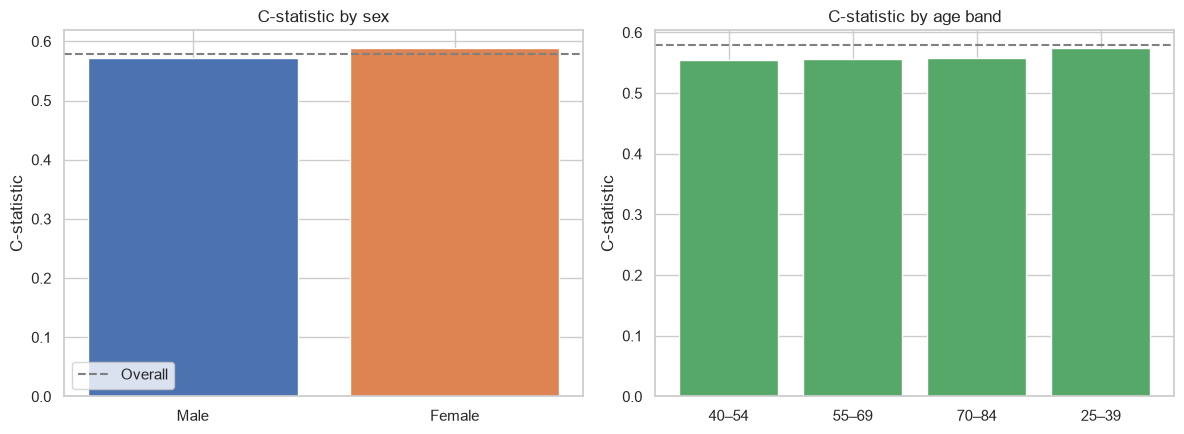

In [8]:
sex_gap = add_gaps(subgroup_metrics(df, "Sex", "sex"), overall)
display(sex_gap[["group", "n", "events", "c_statistic", "r2", "gap_c", "gap_r2"]].round(3))

df["age_band"] = pd.cut(df["age_at_index"], bins=[24, 40, 55, 70, 85], labels=["25–39", "40–54", "55–69", "70–84"])
age_gap = add_gaps(subgroup_metrics(df, "Age band", "age_band"), overall)
display(age_gap[["group", "n", "events", "c_statistic", "gap_c", "gap_oe"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(sex_gap["group"], sex_gap["c_statistic"], color=["#4C72B0", "#DD8452"])
axes[0].axhline(overall["c_statistic"], ls="--", color="gray", label="Overall")
axes[0].set_title("C-statistic by sex")
axes[0].set_ylabel("C-statistic")
axes[0].legend()

axes[1].bar(age_gap["group"].astype(str), age_gap["c_statistic"], color="#55A868")
axes[1].axhline(overall["c_statistic"], ls="--", color="gray")
axes[1].set_title("C-statistic by age band")
axes[1].set_ylabel("C-statistic")
plt.tight_layout()
plt.show()

## 8. Gap from missing / partial predictor capture

In [9]:
# Smoking missingness (among scoreable — BMI required; smoking may still be missing)
df["smoke_data"] = np.where(df["smoke_missing"], "Smoking missing (default Non)", "Smoking recorded")
smoke_gap = add_gaps(subgroup_metrics(df, "Smoking capture", "smoke_data"), overall)
display(smoke_gap[["group", "n", "c_statistic", "gap_c", "gap_oe"]].round(3))

# Family history captured vs not
df["fhdm_data"] = np.where(df["fhdm"], "FH diabetes recorded", "FH missing/absent")
fh_gap = add_gaps(subgroup_metrics(df, "Family history", "fhdm_data"), overall)
display(fh_gap[["group", "n", "c_statistic", "gap_c"]].round(3))

# HTN coding pattern
df["htn_pattern"] = "Neither"
df.loc[df["htn"], "htn_pattern"] = "Treated (dx+med)"
df.loc[df["htn_dx_only"], "htn_pattern"] = "Dx only (QDiabetes=False)"
df.loc[df["htn_med_only"], "htn_pattern"] = "Med only (QDiabetes=False)"
htn_gap = add_gaps(subgroup_metrics(df, "HTN pattern", "htn_pattern"), overall)
display(htn_gap[["group", "n", "events", "c_statistic", "gap_c", "event_rate_pct"]].round(3))

,group,n,c_statistic,gap_c,gap_oe
0,Smoking missing (default Non),16200.0,0.575,-0.004,0.024
1,Smoking recorded,27632.0,0.581,0.002,-0.013


,group,n,c_statistic,gap_c
0,FH diabetes recorded,12704.0,0.560,-0.019
1,FH missing/absent,31128.0,0.579,0.000


,group,n,events,c_statistic,gap_c,event_rate_pct
1,Med only (QDiabetes=False),1215.0,167.0,0.568,-0.011,13.745
2,Neither,37150.0,3538.0,0.576,-0.003,9.524
0,Dx only (QDiabetes=False),3262.0,493.0,0.585,0.006,15.113
3,Treated (dx+med),2205.0,291.0,0.597,0.018,13.197


## 9. Coverage bias — BMI exclusion impact

In [10]:
n_eligible_no_baseline_dm = len(eligible)
n_scoreable = len(df)
n_bmi_excluded = n_eligible_no_baseline_dm - n_scoreable

coverage_tbl = pd.DataFrame({
    "group": ["Scoreable (BMI present)", "Excluded (BMI missing)", "Eligible total"],
    "patients": [n_scoreable, n_bmi_excluded, n_eligible_no_baseline_dm],
    "pct": [
        100 * n_scoreable / n_eligible_no_baseline_dm,
        100 * n_bmi_excluded / n_eligible_no_baseline_dm,
        100.0,
    ],
})
display(coverage_tbl.round(1))
print("BMI exclusion creates coverage bias — excluded patients cannot be scored by QDiabetes.")

,group,patients,pct
0,Scoreable (BMI present),43832,69.5
1,Excluded (BMI missing),19246,30.5
2,Eligible total,63078,100.0


BMI exclusion creates coverage bias — excluded patients cannot be scored by QDiabetes.


## 10. Consolidated gap summary table

In [11]:
all_gaps = pd.concat([
    eth_q,
    eth_n,
    emirati_gap,
    sex_gap,
    age_gap,
    smoke_gap,
    fh_gap,
    htn_gap,
], ignore_index=True)

summary_cols = [
    "group_type", "group", "n", "events", "event_rate_pct",
    "c_statistic", "r2", "calibration_slope", "oe_ratio",
    "gap_c", "gap_r2", "gap_cal_slope", "gap_oe", "metrics_note",
]
gap_summary = all_gaps[summary_cols].sort_values(["group_type", "gap_c"], na_position="last")
display(gap_summary.round(3))

gap_summary.to_csv("output/qdiabetes_gap_analysis.csv", index=False)
print("Saved: output/qdiabetes_gap_analysis.csv")

,group_type,group,n,events,event_rate_pct,c_statistic,r2,calibration_slope,oe_ratio,gap_c,gap_r2,gap_cal_slope,gap_oe,metrics_note
22,Age band,40–54,11494.0,1197.0,10.414,0.555,0.021,0.153,0.723,-0.024,-0.018,-0.031,0.001,
23,Age band,55–69,11322.0,1250.0,11.040,0.556,0.030,0.177,0.530,-0.023,-0.009,-0.007,-0.192,
24,Age band,70–84,6890.0,909.0,13.193,0.559,0.022,0.181,0.626,-0.020,-0.018,-0.003,-0.096,
25,Age band,25–39,14126.0,1133.0,8.021,0.575,0.025,0.181,1.504,-0.004,-0.014,-0.003,0.782,
18,Emirati flag,Non-Emirati,35991.0,3694.0,10.264,0.578,0.039,0.181,0.671,-0.001,-0.000,-0.003,-0.051,
19,Emirati flag,Emirati,7841.0,795.0,10.139,0.587,0.056,0.232,1.111,0.008,0.017,0.048,0.390,
28,Family history,FH diabetes recorded,12704.0,1561.0,12.287,0.560,0.024,0.142,0.646,-0.019,-0.015,-0.042,-0.076,
29,Family history,FH missing/absent,31128.0,2928.0,9.406,0.579,0.039,0.189,0.770,0.000,-0.000,0.005,0.048,
30,HTN pattern,Med only (QDiabetes=False),1215.0,167.0,13.745,0.568,0.018,0.155,0.990,-0.011,-0.022,-0.029,0.269,
31,HTN pattern,Neither,37150.0,3538.0,9.524,0.576,0.037,0.180,0.682,-0.003,-0.002,-0.003,-0.040,


Saved: output/qdiabetes_gap_analysis.csv


## 11. Heatmap — discrimination gap across key subgroups

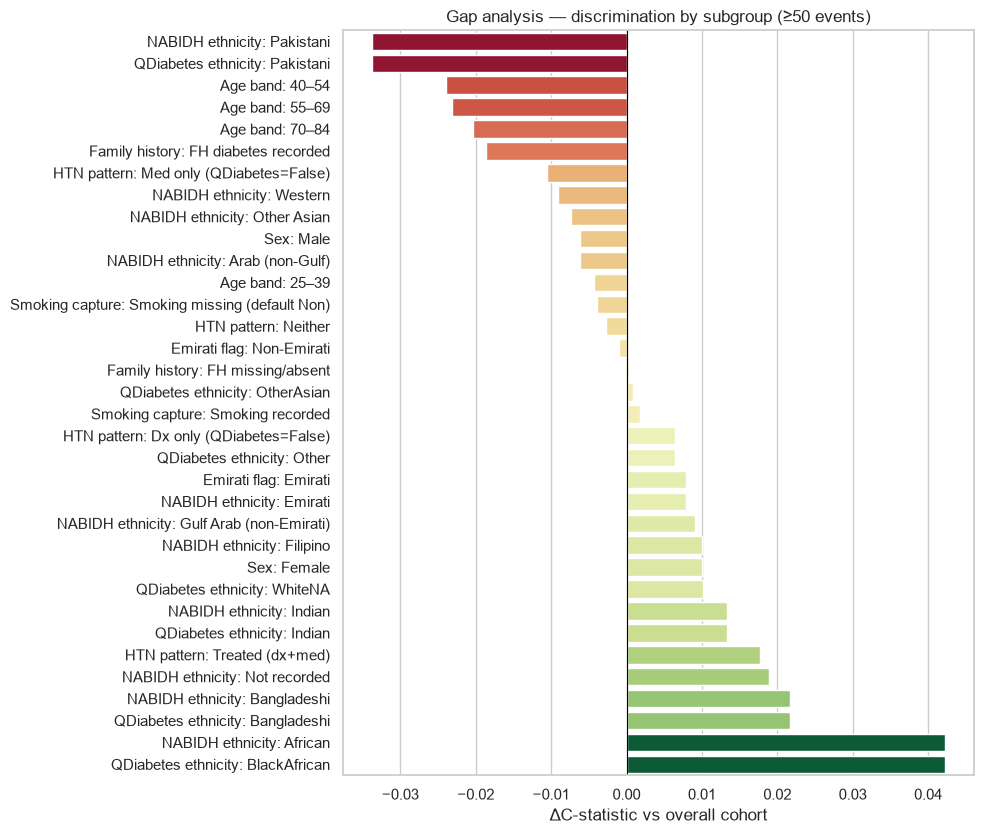

In [12]:
gap_eligible = gap_summary[gap_summary["events"] >= MIN_EVENTS_GAP].copy()

heatmap_df = gap_eligible.copy()
heatmap_df["label"] = heatmap_df["group_type"] + ": " + heatmap_df["group"]
heatmap_df = heatmap_df.dropna(subset=["gap_c"]).sort_values("gap_c")

fig, ax = plt.subplots(figsize=(10, max(6, len(heatmap_df) * 0.25)))
sns.barplot(data=heatmap_df, y="label", x="gap_c", ax=ax, palette="RdYlGn", hue="gap_c", legend=False)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("ΔC-statistic vs overall cohort")
ax.set_ylabel("")
ax.set_title(f"Gap analysis — discrimination by subgroup (≥{MIN_EVENTS_GAP} events)")
plt.tight_layout()
plt.show()

## 12. Written validation summary

In [13]:
ETHNICITY_GROUP_TYPES = {"QDiabetes ethnicity", "NABIDH ethnicity", "Emirati flag"}
gap_rank = gap_summary[gap_summary["events"] >= MIN_EVENTS_GAP].dropna(subset=["gap_c"])
gap_rank_non_eth = gap_rank[~gap_rank["group_type"].isin(ETHNICITY_GROUP_TYPES)]
worst_c = gap_rank_non_eth.nsmallest(3, "gap_c")[["group_type", "group", "gap_c", "c_statistic", "events"]]
best_c = gap_rank_non_eth.nlargest(3, "gap_c")[["group_type", "group", "gap_c", "c_statistic", "events"]]
worst_oe = gap_rank.dropna(subset=["gap_oe"]).nsmallest(3, "gap_oe")[["group_type", "group", "gap_oe", "oe_ratio", "events"]]

print("=" * 76)
print("QDIABETES-2018 MODEL A — VALIDATION & GAP ANALYSIS SUMMARY")
print("SYNTHETIC UAE COHORT — NOT REAL PATIENT DATA")
print("=" * 76)
print(f"N scoreable: {overall['n']:,.0f} | Events: {overall['events']:,.0f} ({overall['event_rate_pct']:.1f}%)")
print(f"C-statistic: {overall['c_statistic']:.3f}  (UK benchmark ~0.86–0.87; not interpretable as UAE performance)")
print(f"R²: {overall['r2']:.3f}  (UK benchmark ~0.53–0.56)")
print(f"Calibration slope: {overall['calibration_slope']:.3f}  (ideal 1.0; logit-scale logistic regression)")
print(calibration_consistency_note(overall["calibration_slope"], overall["c_statistic"]))
print(f"O:E ratio: {overall['oe_ratio']:.3f}  (ideal 1.0; short follow-up caveat)")
print()
print(f"Largest discrimination gaps (worst vs overall; ≥{MIN_EVENTS_GAP} events only):")
for _, r in worst_c.iterrows():
    print(f"  • {r['group_type']} / {r['group']}: ΔC={r['gap_c']:+.3f} (C={r['c_statistic']:.3f}, events={int(r['events'])})")
print()
print(f"Best discrimination vs overall (≥{MIN_EVENTS_GAP} events; ethnicity subgroups excluded):")
for _, r in best_c.iterrows():
    print(f"  • {r['group_type']} / {r['group']}: ΔC={r['gap_c']:+.3f} (C={r['c_statistic']:.3f}, events={int(r['events'])})")
print()
print(f"Largest calibration gaps (O:E vs overall; ≥{MIN_EVENTS_GAP} events only):")
for _, r in worst_oe.iterrows():
    print(f"  • {r['group_type']} / {r['group']}: ΔO:E={r['gap_oe']:+.3f} (O:E={r['oe_ratio']:.3f}, events={int(r['events'])})")
print()
print("Key pipeline conclusions (not real-world performance claims):")
print("  1. Metrics pipeline runs end-to-end on synthetic NABIDH-shaped data")
print("  2. Emirati/Gulf Arab → QDiabetes 'Other' is a structural under-prediction risk to test on real data")
print("  3. HTN dx-only/med-only patients are invisible to QDiabetes treated-HTN rule")
print("  4. O:E requires longer follow-up than available for absolute calibration")
print(f"  5. Gap headline rankings exclude subgroups with <{MIN_EVENTS_GAP} events")
print("=" * 76)

QDIABETES-2018 MODEL A — VALIDATION & GAP ANALYSIS SUMMARY
SYNTHETIC UAE COHORT — NOT REAL PATIENT DATA
N scoreable: 43,832 | Events: 4,489 (10.2%)
C-statistic: 0.579  (UK benchmark ~0.86–0.87; not interpretable as UAE performance)
R²: 0.039  (UK benchmark ~0.53–0.56)
Calibration slope: 0.184  (ideal 1.0; logit-scale logistic regression)
Calibration consistency: slope=0.184 with C=0.579 — review decile plot if slope looks extreme.
O:E ratio: 0.722  (ideal 1.0; short follow-up caveat)

Largest discrimination gaps (worst vs overall; ≥50 events only):
  • Age band / 40–54: ΔC=-0.024 (C=0.555, events=1197)
  • Age band / 55–69: ΔC=-0.023 (C=0.556, events=1250)
  • Age band / 70–84: ΔC=-0.020 (C=0.559, events=909)

Best discrimination vs overall (≥50 events; ethnicity subgroups excluded):
  • HTN pattern / Treated (dx+med): ΔC=+0.018 (C=0.597, events=291)
  • Sex / Female: ΔC=+0.010 (C=0.589, events=1930)
  • HTN pattern / Dx only (QDiabetes=False): ΔC=+0.006 (C=0.585, events=493)

Largest 